# SCT ML Task 2 — Mall Customer Segmentation (K-Means Clustering)
**Internship:** SkillCraft Technology · Machine Learning  
**Objective:** Group mall customers into segments by their purchasing behaviour using K-Means (unsupervised learning, so there is no "right answer" column).

**Dataset:** *Mall Customer Segmentation Data* (200 customers), widely shared on Kaggle: https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python  
This notebook downloads a public GitHub copy (no login).

| Column | Meaning |
|---|---|
| `CustomerID` | Unique ID (not used) |
| `Gender`, `Age` | Demographics (not used for clustering) |
| `Annual Income (k$)` | Income in thousands of dollars → **feature** |
| `Spending Score (1-100)` | Score assigned by the mall from spending behaviour → **feature** |

## 1. Imports

In [1]:
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
SEED = 42
np.random.seed(SEED)
%matplotlib inline

## 2. Load and inspect
If the download fails, upload `Mall_Customers.csv` to Colab and re-run.

In [2]:
URL = "https://raw.githubusercontent.com/MoustafaMohamed01/Mall-Customer-Segmentation-Data/main/Mall_Customers.csv"
try:
    df = pd.read_csv("Mall_Customers.csv") if os.path.exists("Mall_Customers.csv") else pd.read_csv(URL)
except Exception as e:
    raise SystemExit(f"Could not load data ({e}). Download Mall_Customers.csv from Kaggle and upload it.")

F1, F2 = "Annual Income (k$)", "Spending Score (1-100)"
assert all(c in df.columns for c in [F1, F2]), f"Expected columns not found: {list(df.columns)}"
print("Shape:", df.shape)
df.head()

Shape: (200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [3]:
df.info()
df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


,count,mean,std,min,25%,50%,75%,max
CustomerID,200.0,100.50,57.879185,1.0,50.75,100.5,150.25,200.0
Age,200.0,38.85,13.969007,18.0,28.75,36.0,49.00,70.0
Annual Income (k$),200.0,60.56,26.264721,15.0,41.50,61.5,78.00,137.0
Spending Score (1-100),200.0,50.20,25.823522,1.0,34.75,50.0,73.00,99.0


## 3. Clean the data

In [4]:
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate CustomerIDs:", df["CustomerID"].duplicated().sum())
df = df.dropna().drop_duplicates()
print("Rows after cleaning:", len(df))

Missing values: 0
Duplicate rows: 0
Duplicate CustomerIDs: 0
Rows after cleaning: 200


## 4. Explore the two chosen features

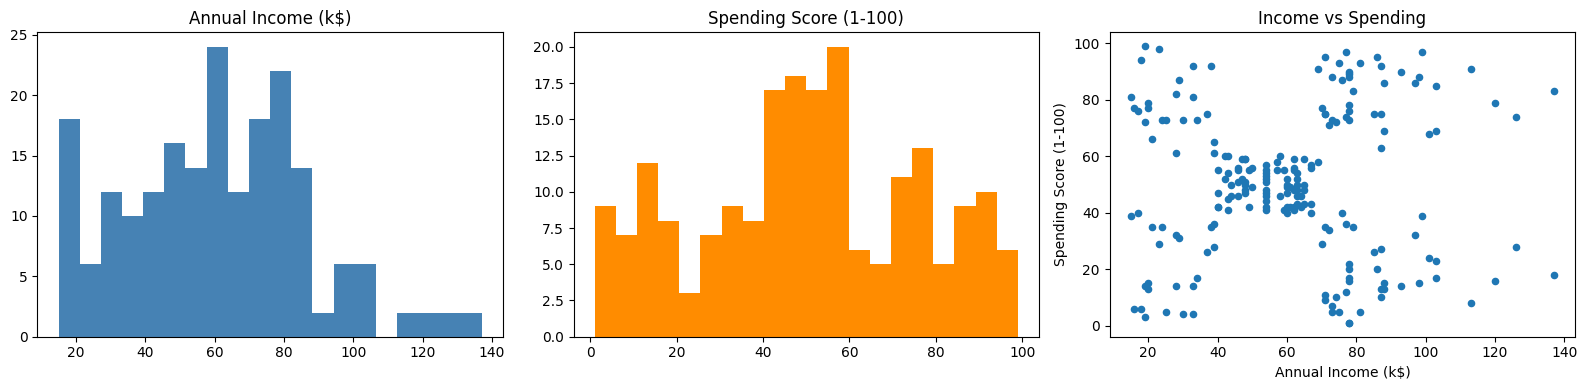

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].hist(df[F1], bins=20, color="steelblue"); ax[0].set_title(F1)
ax[1].hist(df[F2], bins=20, color="darkorange"); ax[1].set_title(F2)
ax[2].scatter(df[F1], df[F2], s=20); ax[2].set_xlabel(F1); ax[2].set_ylabel(F2); ax[2].set_title("Income vs Spending")
plt.tight_layout(); plt.show()

## 5. Standardise features
K-Means uses distances, so features on different scales would be weighted unequally. `StandardScaler` rescales each to mean 0, std 1.

In [6]:
X = df[[F1, F2]].values
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

## 6. Elbow Method (and silhouette check)
Inertia = total squared distance of points to their cluster centre. We look for the "elbow" where adding clusters stops helping much. Silhouette score (higher is better, max 1) gives a second opinion.

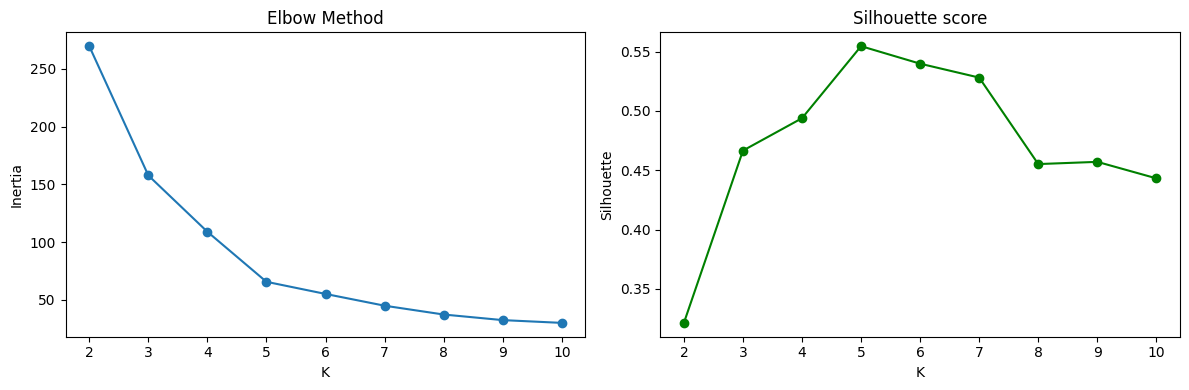

K= 2  inertia= 269.69  silhouette=0.321
K= 3  inertia= 157.70  silhouette=0.467
K= 4  inertia= 108.92  silhouette=0.494
K= 5  inertia=  65.57  silhouette=0.555
K= 6  inertia=  55.06  silhouette=0.540
K= 7  inertia=  44.86  silhouette=0.528
K= 8  inertia=  37.23  silhouette=0.455
K= 9  inertia=  32.39  silhouette=0.457
K=10  inertia=  29.98  silhouette=0.443


In [7]:
ks = range(2, 11)
inertias, sils = [], []
for k in ks:
    km = KMeans(n_clusters=k, random_state=SEED, n_init=10).fit(X_scaled)
    inertias.append(km.inertia_); sils.append(silhouette_score(X_scaled, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(list(ks), inertias, "o-"); ax[0].set_xlabel("K"); ax[0].set_ylabel("Inertia"); ax[0].set_title("Elbow Method")
ax[1].plot(list(ks), sils, "o-", color="green"); ax[1].set_xlabel("K"); ax[1].set_ylabel("Silhouette"); ax[1].set_title("Silhouette score")
plt.tight_layout(); plt.show()
for k, i, s in zip(ks, inertias, sils): print(f"K={k:2d}  inertia={i:7.2f}  silhouette={s:.3f}")

## 7. Fit the final model
Choose K from the two plots above (the curve flattens and the silhouette is highest around the same value).

In [8]:
best_k = list(ks)[int(np.argmax(sils))]
print("K with highest silhouette:", best_k)
K = best_k   # you may set K manually after studying the elbow plot
kmeans = KMeans(n_clusters=K, random_state=SEED, n_init=10).fit(X_scaled)
df["Cluster"] = kmeans.labels_
centroids = scaler.inverse_transform(kmeans.cluster_centers_)   # back to original units
print(f"Final K = {K}, silhouette = {silhouette_score(X_scaled, kmeans.labels_):.3f}")

K with highest silhouette: 5
Final K = 5, silhouette = 0.555


## 8. Visualise clusters and centroids

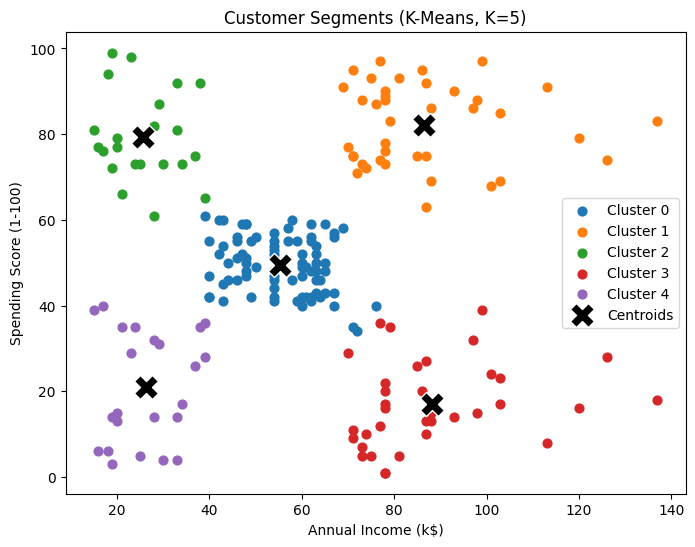

In [9]:
plt.figure(figsize=(8, 6))
cmap = plt.get_cmap("tab10")
for c in range(K):
    pts = df[df.Cluster == c]
    plt.scatter(pts[F1], pts[F2], s=40, color=cmap(c), label=f"Cluster {c}")
plt.scatter(centroids[:, 0], centroids[:, 1], s=300, c="black", marker="X", edgecolors="white", label="Centroids")
plt.xlabel(F1); plt.ylabel(F2); plt.title(f"Customer Segments (K-Means, K={K})"); plt.legend(); plt.show()

## 9. Profile each cluster

In [10]:
profile = df.groupby("Cluster").agg(
    Customers=("CustomerID", "count"),
    Avg_Income_k=(F1, "mean"), Avg_Spending=(F2, "mean"), Avg_Age=("Age", "mean")).round(1)
profile

,Customers,Avg_Income_k,Avg_Spending,Avg_Age
Cluster,,,,
0,81,55.3,49.5,42.7
1,39,86.5,82.1,32.7
2,22,25.7,79.4,25.3
3,35,88.2,17.1,41.1
4,23,26.3,20.9,45.2


**Cluster names from the profile table above (run with seed 42, K=5):**
| Cluster | Customers | Avg income / spending | Segment |
|---|---|---|---|
| 0 | 81 | ~55k / ~50 | Average shoppers (mid income, mid spending) |
| 1 | 39 | ~87k / ~82 | Premium loyal customers |
| 2 | 22 | ~26k / ~79 | Young budget enthusiasts (avg. age ~25) |
| 3 | 35 | ~88k / ~17 | High-income, low-spending (untapped potential) |
| 4 | 23 | ~26k / ~21 | Low-income, low-spending |

*Cluster numbers can change if you change the seed or K; re-read the table if you do.*

## 10. Interpretation and business use
Read the profile table above and name each cluster from its average income and spending, e.g.:
- **High income / high spending** → loyal premium shoppers: VIP programmes, early access to new products.
- **High income / low spending** → under-served wealthy shoppers: targeted promotions, luxury or experience offers.
- **Low income / high spending** → enthusiastic budget shoppers: loyalty points, discounts, instalment offers.
- **Mid income / mid spending** → the average majority: general promotions, upselling.
- **Low income / low spending** → price-sensitive, low engagement: low-cost outreach only.

**Important:** clusters are *patterns in the two features we chose*, not fixed customer identities. A different feature set, scaling or K would give different groups, and K-Means assumes roughly round, similar-sized clusters. The dataset is small (200 rows) and may be synthetic, so treat findings as a demonstration of the method.

## 11. Conclusion
Customers were standardised, K was chosen with the elbow and silhouette methods, and K-Means produced distinct income–spending segments that can guide targeted marketing.